# HW02-2：房地产上市公司财务特征分析

- **姓名：** 魏致衡
- **学号（公开仓库）：** LN429（坚果云提交版使用完整学号）
- **教师作业页面：** https://lianxhcn.github.io/FinEco/exercises/hw-02.html
- **个人 GitHub 仓库访问地址：** https://github.com/lh3536/FinEco-hw
- **HW02-1 目录：** https://github.com/lh3536/FinEco-hw/tree/main/hw02-1
- **HW02-2 目录：** https://github.com/lh3536/FinEco-hw/tree/main/hw02-2
- **数据来源：** CSMAR 上市公司基本信息年度表、上市状态变更表、中国上市公司股权性质文件、资产负债表、利润表
- **下载日期：** 2026-09-28
- **正式样本期：** 2005—2015；资产负债表额外包含 2004-12-31 以构造 2005 年平均资产/权益
- **AI 使用声明：** 使用 ChatGPT / Codex 辅助作业要求提取、CSV 解析、变量字典、数据清洗/合并、QA、绘图与文字组织。本人核验了 2012 版证监会行业 C 的年度历史口径、产权分类、合并报表 `Typrep=A`、2004 年滞后分母、短/长期借款字段、上市状态解析和异常比率；没有静默删除异常观测或把借款缺失填为 0。

## 分析目的与总体思路

本题按**公司—年度**颗粒度构造 2005—2015 年房地产 A 股上市公司非平衡面板。行业和产权均使用当年历史值，不用当前状态回填过去；年末已终止上市的公司才从当年样本排除，暂停上市仍视为上市公司。随后构造资产负债率、`bankloan`、短期负债占比、ROA、ROE、`Cash_TA` 六项指标，比较全部样本的均值/中位数，以及国有与民营企业的年度均值和中位数。

## 1. 原始表、颗粒度与变量字典

原始数据目录保持只读。所有财务表在下载时已使用“合并报表 + 年报（12-31）”条件；Notebook 仍再次核验 `Typrep` 和日期。资产负债表使用包含短期借款与长期借款的新版文件。

特别注意：CSMAR 资产负债表中的原始字段名是“短期借款”和“长期借款”。长期借款字段说明明确为“向银行或其他金融机构借入的一年以上借款”；短期借款为一年期以下（含一年）的借款。本作业按教师统一口径把二者之和作为 `bankloan` 的借款分子，并保留原始字段名称与说明，不将缺失自动记为 0。

In [1]:
from pathlib import Path
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 180)
# 自动选择当前系统实际可用的中文字体，避免 Matplotlib findfont / 缺字警告
from matplotlib import font_manager
_preferred_fonts = ["Microsoft YaHei", "SimHei", "Noto Sans CJK JP", "Noto Sans CJK SC", "Arial Unicode MS"]
_available_fonts = {f.name for f in font_manager.fontManager.ttflist}
_chosen_font = next((f for f in _preferred_fonts if f in _available_fonts), None)
if _chosen_font is not None:
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = [_chosen_font]
else:
    warnings.warn("未检测到常见中文字体；图中中文可能无法正常显示。")
plt.rcParams["axes.unicode_minus"] = False

RAW=Path("data/raw"); OUT_FIG=Path("output/figures"); OUT_TAB=Path("output/tables")
OUT_FIG.mkdir(parents=True,exist_ok=True); OUT_TAB.mkdir(parents=True,exist_ok=True)

def find_one(name):
    hits=list(RAW.rglob(name))
    assert hits, f"未找到 {name}"
    return hits

files = {
    "company_annual": find_one("STK_LISTEDCOINFOANL.csv")[0],
    "listing_change": find_one("STK_ITEMCHANGE.csv")[0],
    "ownership": find_one("EN_EquityNatureAll.csv")[0],
    "income": find_one("FS_Comins.csv")[0],
}
# 资产负债表有两个版本，选择含短期借款 A002101000 与长期借款 A002201000 的新版
bs_candidates=find_one("FS_Combas.csv")
bs_path=None
for p in bs_candidates:
    cols=pd.read_csv(p,encoding="utf-8-sig",nrows=1).columns
    if {"A002101000","A002201000"}.issubset(cols): bs_path=p
assert bs_path is not None
files["balance"] = bs_path

variable_dict = pd.DataFrame([
 ["上市公司基本信息年度表","Symbol","code","股票代码","字符","补齐为6位"],
 ["上市公司基本信息年度表","IndustryCodeC","industry_code","2012版证监会行业C","字符","逐年历史行业；K70=房地产业"],
 ["上市公司基本信息年度表","LISTINGDATE","listing_date","首次上市日期","日期","用于年末是否已上市"],
 ["股权性质文件","EquityNatureID","ownership","股权性质编码","分类","1国企、2民营、3外资、4其他；缺失=Unknown"],
 ["资产负债表","A001000000","total_assets","资产总计","金额","合并口径"],
 ["资产负债表","A002000000","total_liabilities","负债合计","金额","合并口径"],
 ["资产负债表","A002100000","current_liabilities","流动负债合计","金额","短期负债占比的分子"],
 ["资产负债表","A002101000","short_term_loan","短期借款","金额","bankloan 分子之一；缺失不补0"],
 ["资产负债表","A002201000","long_term_loan","长期借款","金额","bankloan 分子之一；缺失不补0"],
 ["资产负债表","A003000000","total_equity","所有者权益合计","金额","与合并净利润保持口径一致"],
 ["资产负债表","A001101000","monetary_funds","货币资金","金额","Cash_TA 分子"],
 ["利润表","B002000000","net_income","净利润","金额","合并净利润"],
],columns=["source_file","raw_variable","clean_variable","definition","unit","note"])
display(variable_dict)
variable_dict.to_csv(OUT_TAB/"hw02-2-variable-dictionary.csv",index=False,encoding="utf-8-sig")
print("选用资产负债表：", files["balance"])

,source_file,raw_variable,clean_variable,definition,unit,note
0,上市公司基本信息年度表,Symbol,code,股票代码,字符,补齐为6位
1,上市公司基本信息年度表,IndustryCodeC,industry_code,2012版证监会行业C,字符,逐年历史行业；K70=房地产业
2,上市公司基本信息年度表,LISTINGDATE,listing_date,首次上市日期,日期,用于年末是否已上市
3,股权性质文件,EquityNatureID,ownership,股权性质编码,分类,1国企、2民营、3外资、4其他；缺失=Unknown
4,资产负债表,A001000000,total_assets,资产总计,金额,合并口径
5,资产负债表,A002000000,total_liabilities,负债合计,金额,合并口径
6,资产负债表,A002100000,current_liabilities,流动负债合计,金额,短期负债占比的分子
7,资产负债表,A002101000,short_term_loan,短期借款,金额,bankloan 分子之一；缺失不补0
8,资产负债表,A002201000,long_term_loan,长期借款,金额,bankloan 分子之一；缺失不补0
9,资产负债表,A003000000,total_equity,所有者权益合计,金额,与合并净利润保持口径一致


选用资产负债表： data/raw/05-income-statement/#U8d44#U4ea7#U8d1f#U503a#U8868221438189(#U4ec5#U4f9b#U4e2d#U5c71#U5927#U5b66#U4f7f#U7528)/FS_Combas.csv


**字段审计。** 变量构造完全来自原始财务科目，而不是下载现成比率。货币资金、资产、负债、权益、短期借款、长期借款和净利润都保留统一合并口径；比率本身无量纲，因此金额币种/缩放不会影响结果，但跨表必须保持同一口径。新版资产负债表同时覆盖 2004—2015，为平均资产和平均权益提供必要的滞后值。

## 2. 上市状态 CSV 安全解析与房地产年度样本

`STK_ITEMCHANGE.csv` 的 `Comments` 含公告长文本、内嵌换行和不规则引号，普通 `read_csv` 会在部分行把备注中的逗号误判成新字段。这里**不使用 `skip_bad_lines`**，也不静默丢记录；而是逐物理行只解析作业需要的前 9 个结构化字段，利用每条真实记录都以 6 位证券代码和日期字段开头的固定格式识别记录。备注 `Comments` 不参与年末上市状态判断，因此不需要强行解析。

In [2]:
# 2.1 公司年度信息
info=pd.read_csv(files["company_annual"],encoding="utf-8-sig",dtype=str)
info["code"]=info["Symbol"].str.zfill(6)
info["date"]=pd.to_datetime(info["EndDate"]); info["year"]=info["date"].dt.year
info["listing_date"]=pd.to_datetime(info["LISTINGDATE"],errors="coerce")
assert info.duplicated(["code","year"]).sum()==0

# 2.2 安全恢复上市状态结构化字段
pat=re.compile(r'^"(?P<Symbol>\d{6})","(?P<DeclareDate>[^"]*)","(?P<ChangeDate>[^"]*)","(?P<ChangedItem>[^"]*)","(?P<InstitutionID>[^"]*)","(?P<ValueBefore>[^"]*)","(?P<ValueAfter>[^"]*)","(?P<VALUE>[^"]*)","(?P<ReasonID>[^"]*)",')
rows=[]
with open(files["listing_change"],encoding="utf-8-sig") as f:
    for line in f:
        m=pat.match(line)
        if m: rows.append(m.groupdict())
changes=pd.DataFrame(rows)
changes["ChangeDate"]=pd.to_datetime(changes["ChangeDate"],errors="coerce")
status=changes[changes["ChangedItem"].eq("上市状态")].copy()
print(f"安全恢复变更记录：{len(changes):,}；其中上市状态记录：{len(status):,}")
print(changes["ChangedItem"].value_counts())

# 2.3 按当年行业筛房地产；要求年末已完成首次上市
re_raw=info[(info["year"].between(2005,2015)) & info["IndustryCodeC"].eq("K70")].copy()
re_listed=re_raw[re_raw["listing_date"]<=re_raw["date"]].copy()

# 对每个 firm-year 取年末之前最近一次“上市状态”变化；无变化且已上市则视为正常上市
latest_status=[]
for r in re_listed[["code","date"]].itertuples(index=False):
    s=status[(status["Symbol"].eq(r.code)) & (status["ChangeDate"]<=r.date)].sort_values("ChangeDate")
    latest_status.append(s.iloc[-1]["ValueAfter"] if len(s) else "正常上市")
re_listed["yearend_status"]=latest_status
sample=re_listed[re_listed["yearend_status"].ne("终止上市")].copy()
assert sample.duplicated(["code","year"]).sum()==0

sample_processing=[]
def stage(label,df,note):
    sample_processing.append([label,df["code"].nunique(),len(df),note])
stage("房地产行业年度记录（K70）",re_raw,"按当年 IndustryCodeC=K70")
stage("年末已完成首次上市",re_listed,"listing_date <= 12-31")
stage("按年末上市状态保留",sample,"排除年末已终止上市；暂停上市仍属于上市公司")

print("房地产K70原始 firm-year：",len(re_raw),"；年末已上市：",len(re_listed),"；最终上市状态样本：",len(sample))
print("样本不同公司数：",sample["code"].nunique())
print("年末状态分布：")
print(sample["yearend_status"].value_counts())

安全恢复变更记录：1,302；其中上市状态记录：190
ChangedItem
证券简称    1112
上市状态     190
Name: count, dtype: int64


房地产K70原始 firm-year： 1194 ；年末已上市： 1193 ；最终上市状态样本： 1193
样本不同公司数： 172
年末状态分布：
yearend_status
正常上市    1181
暂停上市      12
Name: count, dtype: int64


**样本解读。** 2005—2015 年按历史 `IndustryCodeC=K70` 得到 **1,194** 条房地产公司年度记录；其中 1 条在对应年末尚未完成首次上市，剔除后为 **1,193** 条、**172 家**不同公司。上市状态表安全恢复 **1,302** 条结构化变更记录，其中 **190** 条是“上市状态”变化。最终房地产样本中 1,181 条年末为正常上市、12 条年末为暂停上市；暂停上市并不等于终止上市，因此仍计入“当年上市公司”。这避免了只用当前存续公司向前追溯造成的幸存者偏差。

## 3. 产权属性、合并报表与多表合并

产权使用每年股权性质文件，不用当前产权回填过去。分类规则：`1=SOE`、`2=Private`、`3=外资`与`4=其他`合并为 `Other`，缺失为 `Unknown`；因此“非国有”不会被简单等同为“民营”。

财务表合并前检查 `code-year` 唯一性。ROA/ROE 的滞后资产和权益先在**全部 A 股资产负债表**内按公司计算，再合并到房地产样本，避免因为上一年尚未属于房地产行业而错误丢掉合法的上年末分母。

In [3]:
# 3.1 产权
own=pd.read_csv(files["ownership"],encoding="utf-8-sig",dtype=str)
own["code"]=own["Symbol"].str.zfill(6); own["year"]=pd.to_datetime(own["EndDate"]).dt.year
assert own.duplicated(["code","year"]).sum()==0
own["ownership"]=own["EquityNatureID"].map({"1":"SOE","2":"Private","3":"Other","4":"Other"}).fillna("Unknown")

# 3.2 新版资产负债表
bs=pd.read_csv(files["balance"],encoding="utf-8-sig",dtype={"Stkcd":str})
bs["code"]=bs["Stkcd"].str.zfill(6); bs["date"]=pd.to_datetime(bs["Accper"]); bs["year"]=bs["date"].dt.year
assert set(bs["Typrep"].dropna().unique())=={"A"}; assert (bs["date"].dt.strftime("%m-%d")=="12-31").all(); assert bs.duplicated(["code","year"]).sum()==0
bs=bs.rename(columns={"A001101000":"monetary_funds","A001000000":"total_assets","A002101000":"short_term_loan","A002100000":"current_liabilities","A002201000":"long_term_loan","A002000000":"total_liabilities","A003000000":"total_equity"}).sort_values(["code","year"])
bs["lag_year"]=bs.groupby("code")["year"].shift(1)
bs["assets_lag"]=bs.groupby("code")["total_assets"].shift(1)
bs["equity_lag"]=bs.groupby("code")["total_equity"].shift(1)
bs.loc[bs["lag_year"]!=bs["year"]-1,["assets_lag","equity_lag"]]=np.nan

# 3.3 利润表
inc=pd.read_csv(files["income"],encoding="utf-8-sig",dtype={"Stkcd":str})
inc["code"]=inc["Stkcd"].str.zfill(6); inc["date"]=pd.to_datetime(inc["Accper"]); inc["year"]=inc["date"].dt.year
assert set(inc["Typrep"].dropna().unique())=={"A"}; assert (inc["date"].dt.strftime("%m-%d")=="12-31").all(); assert inc.duplicated(["code","year"]).sum()==0
inc=inc.rename(columns={"B002000000":"net_income"})

panel=sample.merge(own[["code","year","ActualControllerName","ActualControllerNatureID","EquityNature","EquityNatureID","ownership"]],on=["code","year"],how="left",validate="1:1",indicator="merge_ownership")
panel["ownership"]=panel["ownership"].fillna("Unknown")
stage("合并产权",panel,"1:1；缺失产权标记 Unknown")

bs_keep=["code","year","monetary_funds","total_assets","short_term_loan","current_liabilities","long_term_loan","total_liabilities","total_equity","assets_lag","equity_lag"]
panel=panel.merge(bs[bs_keep],on=["code","year"],how="left",validate="1:1",indicator="merge_bs")
stage("合并资产负债表",panel,"1:1；2004滞后信息在全A股表内构造")
panel=panel.merge(inc[["code","year","net_income"]],on=["code","year"],how="left",validate="1:1",indicator="merge_inc")
stage("合并利润表",panel,"1:1；合并净利润")

print("资产负债表年份：",bs["year"].min(),"-",bs["year"].max(),"；行数",len(bs))
print("利润表年份：",inc["year"].min(),"-",inc["year"].max(),"；行数",len(inc))
print("房地产样本财务表未匹配：BS=",(panel["merge_bs"]!="both").sum(),"；IS=",(panel["merge_inc"]!="both").sum())
print("2005年上一年资产/权益匹配：",panel.loc[panel.year.eq(2005),["assets_lag","equity_lag"]].notna().sum().to_dict()," / 公司数",(panel.year==2005).sum())

资产负债表年份： 2004 - 2015 ；行数 24228
利润表年份： 2005 - 2015 ；行数 22871
房地产样本财务表未匹配：BS= 0 ；IS= 0
2005年上一年资产/权益匹配： {'assets_lag': 65, 'equity_lag': 65}  / 公司数 65


**合并核验。** 新版资产负债表覆盖 **2004—2015**，利润表覆盖 **2005—2015**，两表均全部为 `Typrep=A` 的 12 月 31 日合并年报，且 `code-year` 无重复。1,193 条房地产 firm-year 与两张财务表均 **100% 匹配**。2005 年的 65 家房地产公司全部成功匹配到 2004 年末资产和权益，因此 2005 年 ROA/ROE 没有因作业漏下 2004 数据而损失分母。

## 4. 六项指标、分母规则、缺失与离群值审计

$$
\text{leverage}=\frac{L}{A},\quad
\text{bankloan}=\frac{STLoan+LTLoan}{L},\quad
\text{short debt ratio}=\frac{CurrentL}{L}
$$

$$
ROA=\frac{NI}{(A_t+A_{t-1})/2},\quad
ROE=\frac{NI}{(E_t+E_{t-1})/2},\quad
Cash\_TA=\frac{MonetaryFunds}{A}.
$$

处理规则：资产或负债分母为 0 时对应比率记为缺失；短/长期借款任一缺失时 `bankloan` 保持缺失；ROA 要求连续上一年资产；ROE 除要求连续上一年权益外，还要求**平均权益 > 0**。非正平均权益下 ROE 的符号和数量级很难解释，因此不用于 ROE 比较，但保留原始权益并在 QA 中统计。其他极端值不自动缩尾或删除，而是保留并用中位数及异常表检查影响。

In [4]:
# 基础分母 QA
for c in ["monetary_funds","total_assets","short_term_loan","current_liabilities","long_term_loan","total_liabilities","total_equity","net_income","assets_lag","equity_lag"]:
    panel[c]=pd.to_numeric(panel[c],errors="coerce")

panel["avg_assets"]=(panel["total_assets"]+panel["assets_lag"])/2
panel["avg_equity"]=(panel["total_equity"]+panel["equity_lag"])/2
panel["leverage"]=np.where(panel["total_assets"]!=0,panel["total_liabilities"]/panel["total_assets"],np.nan)
panel["bankloan"]=np.where((panel["total_liabilities"]!=0) & panel["short_term_loan"].notna() & panel["long_term_loan"].notna(),(panel["short_term_loan"]+panel["long_term_loan"])/panel["total_liabilities"],np.nan)
panel["short_debt_ratio"]=np.where(panel["total_liabilities"]!=0,panel["current_liabilities"]/panel["total_liabilities"],np.nan)
panel["roa"]=np.where(panel["avg_assets"]>0,panel["net_income"]/panel["avg_assets"],np.nan)
panel["roe"]=np.where(panel["avg_equity"]>0,panel["net_income"]/panel["avg_equity"],np.nan)
panel["cash_ta"]=np.where(panel["total_assets"]!=0,panel["monetary_funds"]/panel["total_assets"],np.nan)
metrics=["leverage","bankloan","short_debt_ratio","roa","roe","cash_ta"]
metric_cn={"leverage":"资产负债率","bankloan":"银行借款占负债","short_debt_ratio":"短期负债占比","roa":"ROA","roe":"ROE","cash_ta":"Cash_TA"}

qa_den=pd.Series({
    "total_assets_zero":int((panel.total_assets==0).sum()),
    "total_liabilities_zero":int((panel.total_liabilities==0).sum()),
    "long_term_loan_missing":int(panel.long_term_loan.isna().sum()),
    "lag_assets_missing":int(panel.assets_lag.isna().sum()),
    "lag_equity_missing":int(panel.equity_lag.isna().sum()),
    "current_equity_negative":int((panel.total_equity<0).sum()),
    "avg_equity_nonpositive":int(((panel.avg_equity<=0)&panel.avg_equity.notna()).sum()),
})
display(qa_den.to_frame("count"))

validN=panel.groupby("year")[metrics].count()
display(validN)
validN.to_csv(OUT_TAB/"hw02-2-yearly-valid-N.csv",encoding="utf-8-sig")

# 离群值审计：只flag，不自动删除
outlier_rules={
    "leverage":(panel.leverage<0)|(panel.leverage>1),
    "bankloan":(panel.bankloan<0)|(panel.bankloan>1),
    "short_debt_ratio":(panel.short_debt_ratio<0)|(panel.short_debt_ratio>1),
    "roa":panel.roa.abs()>1,
    "roe":panel.roe.abs()>1,
    "cash_ta":(panel.cash_ta<0)|(panel.cash_ta>1),
}
outlier_audit=pd.DataFrame({"flag_count":{k:int(v.sum()) for k,v in outlier_rules.items()},
                            "min":panel[metrics].min(),"p01":panel[metrics].quantile(.01),"median":panel[metrics].median(),"p99":panel[metrics].quantile(.99),"max":panel[metrics].max()})
display(outlier_audit.round(4))
outlier_audit.to_csv(OUT_TAB/"hw02-2-outlier-audit.csv",encoding="utf-8-sig")

top_lev=panel.nlargest(8,"leverage")[["code","ShortName","year","ownership","total_assets","total_liabilities","total_equity","leverage"]]
display(top_lev.round(4))

,count
total_assets_zero,0
total_liabilities_zero,0
long_term_loan_missing,2
lag_assets_missing,9
lag_equity_missing,9
current_equity_negative,22
avg_equity_nonpositive,21


,leverage,bankloan,short_debt_ratio,roa,roe,cash_ta
year,,,,,,
2005,65,65,65,65,61,65
2006,68,68,68,66,63,68
2007,74,74,74,72,69,74
2008,86,85,86,85,83,86
2009,104,104,104,102,100,104
2010,123,123,123,123,121,123
2011,128,127,128,128,126,128
2012,142,142,142,142,140,142
2013,135,135,135,135,135,135


,flag_count,min,p01,median,p99,max
leverage,22,0.0282,0.1409,0.6451,1.6661,55.4086
bankloan,0,0.0000,0.0000,0.3162,0.8043,0.9157
short_debt_ratio,0,0.1197,0.2478,0.7470,1.0000,1.0000
roa,5,-1.5424,-0.1565,0.0293,0.2065,2.2450
roe,9,-5.2679,-0.4364,0.0883,0.5354,4.3193
cash_ta,0,0.0002,0.0035,0.1175,0.4942,0.8290


,code,ShortName,year,ownership,total_assets,total_liabilities,total_equity,leverage
843,600603,ST 兴业,2009,Private,4963989.80,2.750479e+08,-2.700839e+08,55.4086
842,600603,ST 兴业,2008,Unknown,15940887.95,2.891829e+08,-2.732421e+08,18.1410
1071,600745,S*ST 天华,2007,Private,14772717.01,1.807940e+08,-1.660213e+08,12.2384
841,600603,ST 兴业,2007,Unknown,34724270.90,3.390908e+08,-3.043666e+08,9.7652
1070,600745,S*ST 天华,2006,Private,26232092.49,2.554106e+08,-2.291785e+08,9.7366
1069,600745,天华股份,2005,Private,27285716.66,2.646390e+08,-2.373533e+08,9.6988
844,600603,ST 兴业,2010,Private,36028819.86,3.113522e+08,-2.753233e+08,8.6418
839,600603,ST 兴业,2005,Unknown,63556086.64,4.949435e+08,-4.313874e+08,7.7875


**QA 解读。** 总资产与总负债没有 0 分母；长期借款只有 **2** 条缺失，因此 `bankloan` 有效样本为 1,191，而不是把这两条强行补成 0。连续上一年资产/权益各缺 **9** 条，主要对应后续新进入样本且缺连续财务历史的公司。另有 **21** 条 firm-year 的平均权益非正，因此 ROE 最终有效样本进一步下降；这是有意的经济口径选择，而不是数据读取失败。

离群值检查显示资产负债率存在少数远大于 1 的公司，例如 2009 年 `ST 兴业` 的资产负债率约 **55.4**，其资产规模很小而负债远大于资产、权益显著为负。2005—2009 年均值因此明显被困境公司拉高，而中位数远稳定得多。此类值具有清楚的资产负债表经济含义，所以本题不为“让图好看”而缩尾；均值与中位数并列展示本身就是重要稳健性检查。

## 5. 年度公司数量与产权结构

公司数按当年 `code` 去重，不因某项财务指标缺失而删公司。图上同时展示总数、SOE/Private/Other/Unknown 数量，以及 SOE 和 Private 占当年全部房地产上市公司的比例。

ownership,Total,SOE,Private,Other,Unknown,SOE_share,Private_share
year,,,,,,,
2005,65,36,26,2,1,0.5538,0.4000
2006,68,38,26,3,1,0.5588,0.3824
2007,74,36,32,4,2,0.4865,0.4324
2008,86,42,37,5,2,0.4884,0.4302
2009,104,53,45,5,1,0.5096,0.4327
2010,123,60,54,8,1,0.4878,0.4390
2011,128,59,57,11,1,0.4609,0.4453
2012,142,67,60,13,2,0.4718,0.4225
2013,135,63,56,14,2,0.4667,0.4148


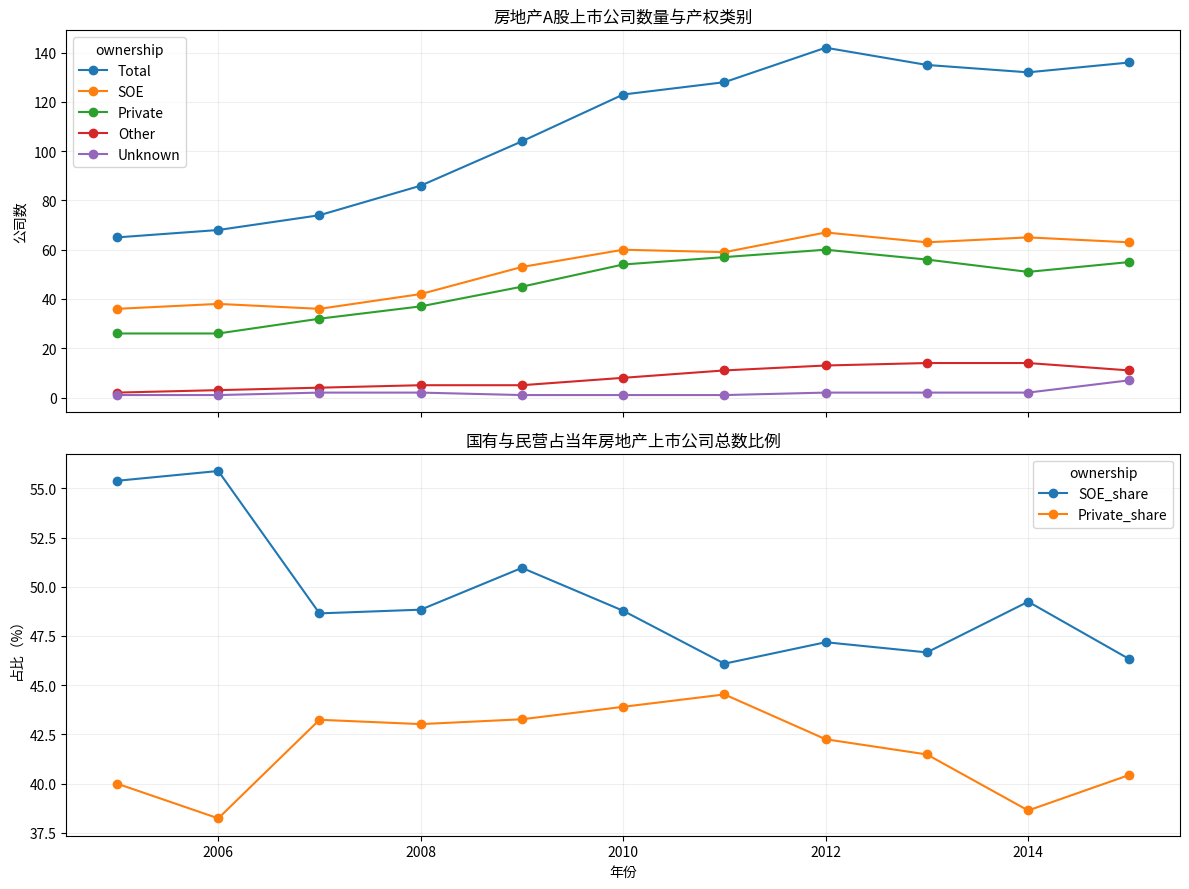

In [5]:
counts=panel.pivot_table(index="year",columns="ownership",values="code",aggfunc="nunique",fill_value=0)
for c in ["SOE","Private","Other","Unknown"]:
    if c not in counts: counts[c]=0
counts["Total"]=panel.groupby("year")["code"].nunique()
counts["SOE_share"]=counts["SOE"]/counts["Total"]
counts["Private_share"]=counts["Private"]/counts["Total"]
counts=counts[["Total","SOE","Private","Other","Unknown","SOE_share","Private_share"]]
display(counts.round(4))
counts.to_csv(OUT_TAB/"hw02-2-ownership-counts.csv",encoding="utf-8-sig")

fig,axes=plt.subplots(2,1,figsize=(12,9),sharex=True)
counts[["Total","SOE","Private","Other","Unknown"]].plot(ax=axes[0],marker="o")
axes[0].set_title("房地产A股上市公司数量与产权类别"); axes[0].set_ylabel("公司数"); axes[0].grid(alpha=.2)
(counts[["SOE_share","Private_share"]]*100).plot(ax=axes[1],marker="o")
axes[1].set_title("国有与民营占当年房地产上市公司总数比例"); axes[1].set_ylabel("占比（%）"); axes[1].set_xlabel("年份"); axes[1].grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT_FIG/"fig01-ownership-structure.png",dpi=160,bbox_inches="tight"); plt.show()

**产权结构解读。** 房地产上市公司数从 **2005 年 65 家**增加到 **2012 年 142 家**，随后回落至 **2015 年 136 家**，体现了上市进入、行业分类变化和退出共同形成的非平衡面板。SOE 数量从 36 家上升到 2012 年的 67 家，Private 从 26 家上升到 60 家；2015 年分别为 63 家和 55 家。SOE 占比由 2005 年约 **55.4%**降至 2015 年约 **46.3%**，Private 占比约从 **40.0%**变为 **40.4%**。由于还有 Other 和 Unknown，两者占比之和并不要求等于 100%。

## 6. 六项财务指标：全部样本年度均值与中位数

均值与中位数并列可以直接观察极端观测对横截面分布的影响。资产负债率按公司比率做算术平均，不使用“行业总负债/行业总资产”的聚合比率。

,year,metric,mean,median,valid_N
0,2005,leverage,0.8672,0.5873,65
1,2005,bankloan,0.4404,0.4566,65
2,2005,short_debt_ratio,0.8475,0.8778,65
3,2005,roa,-0.0187,0.0208,65
4,2005,roe,0.0274,0.0485,61
5,2005,cash_ta,0.1165,0.0810,65
6,2006,leverage,0.7828,0.5953,68
7,2006,bankloan,0.4133,0.4097,68
8,2006,short_debt_ratio,0.7841,0.8247,68
9,2006,roa,0.0192,0.0268,66


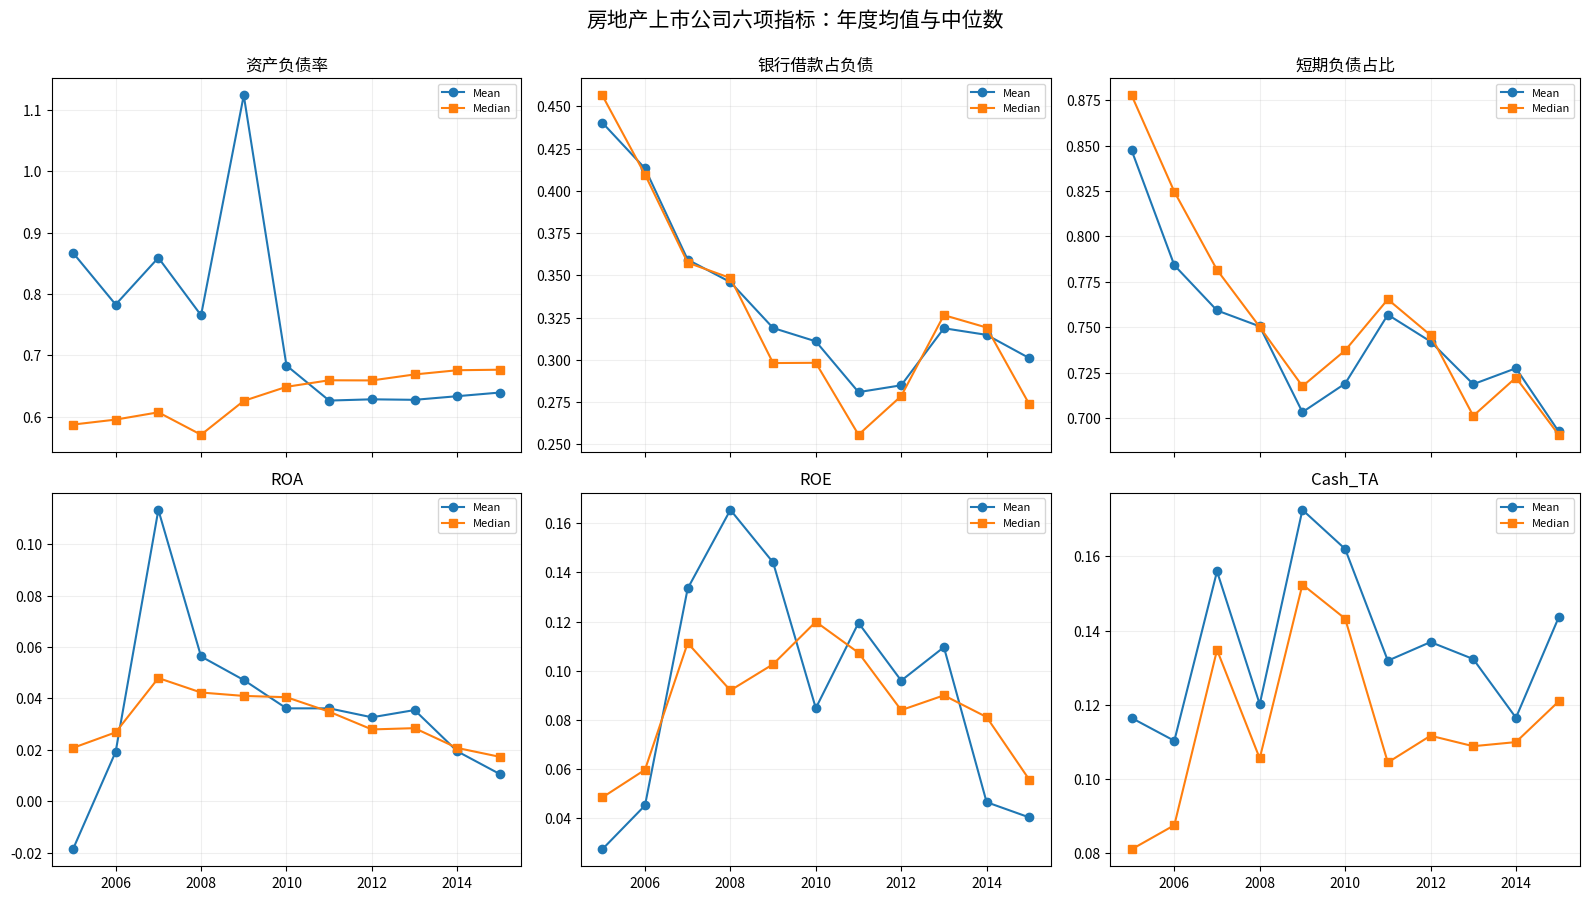

In [6]:
overall=panel.groupby("year")[metrics].agg(["mean","median"])
# 展开成长表便于保存
rows=[]
for y in sorted(panel.year.unique()):
    for m in metrics:
        rows.append([y,m,panel.loc[panel.year.eq(y),m].mean(),panel.loc[panel.year.eq(y),m].median(),panel.loc[panel.year.eq(y),m].count()])
overall_long=pd.DataFrame(rows,columns=["year","metric","mean","median","valid_N"])
display(overall_long.head(12).round(4))
overall_long.to_csv(OUT_TAB/"hw02-2-overall-yearly-summary.csv",index=False,encoding="utf-8-sig")

fig,axes=plt.subplots(2,3,figsize=(16,9),sharex=True)
for ax,m in zip(axes.ravel(),metrics):
    g=overall_long[overall_long.metric.eq(m)]
    ax.plot(g.year,g["mean"],marker="o",label="Mean")
    ax.plot(g.year,g["median"],marker="s",label="Median")
    ax.set_title(metric_cn[m]); ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.suptitle("房地产上市公司六项指标：年度均值与中位数",y=.995,fontsize=15)
fig.tight_layout(); fig.savefig(OUT_FIG/"fig02-overall-mean-median.png",dpi=160,bbox_inches="tight"); plt.show()

**总体时序解读。** 资产负债率均值在 2005、2007、2009 年分别约 **0.87、0.86、1.12**，明显高于同期中位数约 **0.59、0.61、0.63**；这与前述少数负权益困境公司完全一致。2010 年以后均值和中位数显著靠拢，2015 年约为 **0.64 / 0.68**。因此早期均值的高点不能简单解释为“整个行业普遍加杠杆”。

`bankloan` 的均值从 2005 年约 **0.44**降至 2015 年约 **0.30**；短期负债占比从约 **0.85**降至 **0.69**。ROA 在 2007 年均值约 **11.3%**，随后总体下降，到 2015 年约 **1.1%**；ROE 也从危机前后的较高水平回落至 2015 年约 **4.0%**。现金/资产比率在 2009—2010 年较高，2015 年约 **14.4%**。这些都是描述性时序，可能同时受宏观环境、公司进出样本及财务困境观测影响，不能由图形直接推断因果。

## 7. SOE 与 Private：年度均值比较

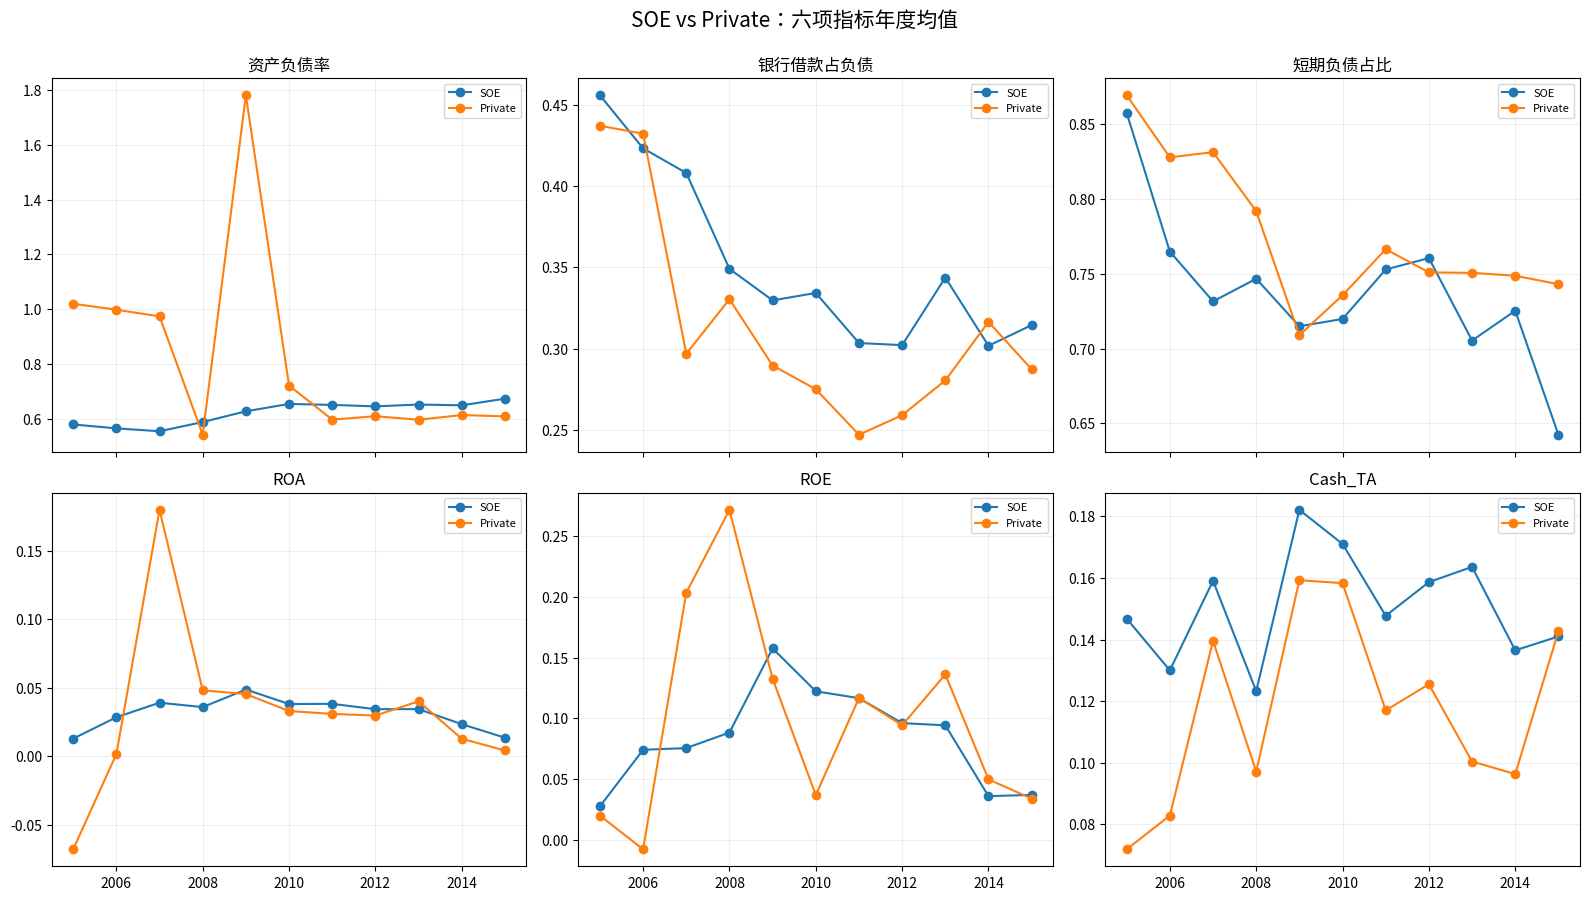

In [7]:
sp=panel[panel["ownership"].isin(["SOE","Private"])].copy()
mean_group=sp.groupby(["year","ownership"])[metrics].mean().reset_index()
fig,axes=plt.subplots(2,3,figsize=(16,9),sharex=True)
for ax,m in zip(axes.ravel(),metrics):
    for o in ["SOE","Private"]:
        g=mean_group[mean_group.ownership.eq(o)]
        ax.plot(g.year,g[m],marker="o",label=o)
    ax.set_title(metric_cn[m]); ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.suptitle("SOE vs Private：六项指标年度均值",y=.995,fontsize=15)
fig.tight_layout(); fig.savefig(OUT_FIG/"fig03-soe-private-mean.png",dpi=160,bbox_inches="tight"); plt.show()
mean_group.to_csv(OUT_TAB/"hw02-2-soe-private-mean.csv",index=False,encoding="utf-8-sig")

**均值组间解读。** 2005 年 Private 的资产负债率均值约 **1.02**，远高于 SOE 的 **0.58**，但这一差距很大程度受民营组少数负权益/困境公司拉动；到 2015 年两组均值约为 **0.61** 与 **0.68**，方向已经反转。`bankloan` 上 SOE 在多数年份均值略高，例如 2015 年约 **0.315** 对 Private 的 **0.287**；短期负债占比则 2015 年 Private 约 **0.743**，高于 SOE 的 **0.643**。这些差异可能与企业规模、融资渠道和样本构成相关，但本题没有控制其他变量，因此不能称为产权的因果效应。

## 8. SOE 与 Private：年度中位数比较

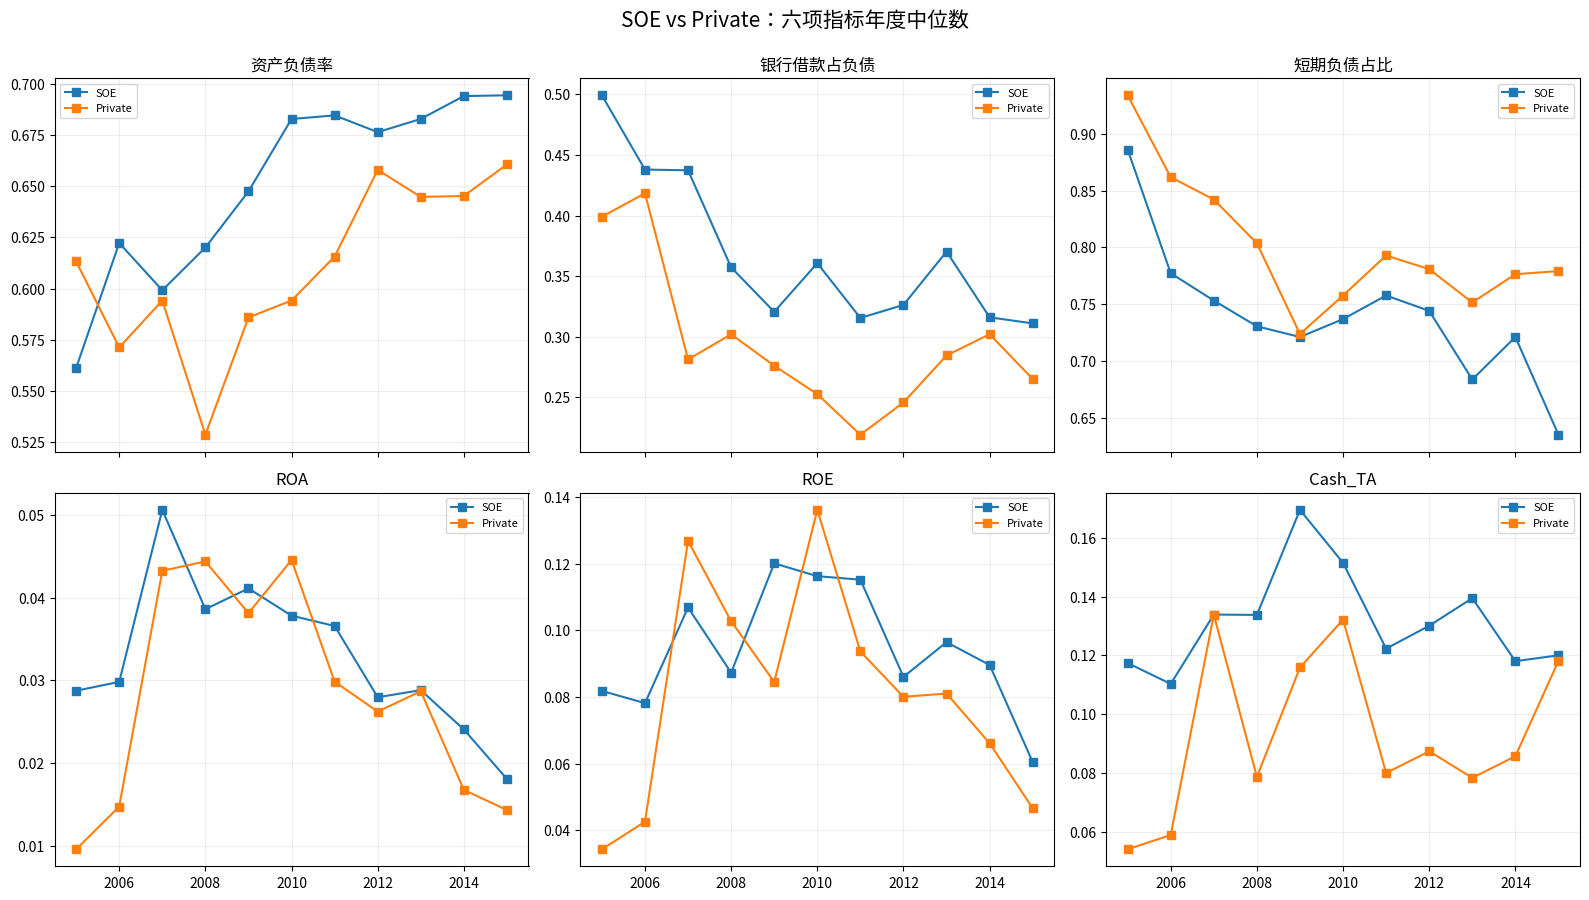

,stage,firms,firm_years,notes
0,房地产行业年度记录（K70）,172,1194,按当年 IndustryCodeC=K70
1,年末已完成首次上市,172,1193,listing_date <= 12-31
2,按年末上市状态保留,172,1193,排除年末已终止上市；暂停上市仍属于上市公司
3,合并产权,172,1193,1:1；缺失产权标记 Unknown
4,合并资产负债表,172,1193,1:1；2004滞后信息在全A股表内构造
5,合并利润表,172,1193,1:1；合并净利润
6,变量构造完成,172,1193,保留全部firm-year；各指标使用自身有效N


In [8]:
median_group=sp.groupby(["year","ownership"])[metrics].median().reset_index()
fig,axes=plt.subplots(2,3,figsize=(16,9),sharex=True)
for ax,m in zip(axes.ravel(),metrics):
    for o in ["SOE","Private"]:
        g=median_group[median_group.ownership.eq(o)]
        ax.plot(g.year,g[m],marker="s",label=o)
    ax.set_title(metric_cn[m]); ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.suptitle("SOE vs Private：六项指标年度中位数",y=.995,fontsize=15)
fig.tight_layout(); fig.savefig(OUT_FIG/"fig04-soe-private-median.png",dpi=160,bbox_inches="tight"); plt.show()
median_group.to_csv(OUT_TAB/"hw02-2-soe-private-median.csv",index=False,encoding="utf-8-sig")

sample_processing_df=pd.DataFrame(sample_processing,columns=["stage","firms","firm_years","notes"])
sample_processing_df.loc[len(sample_processing_df)] = ["变量构造完成",panel.code.nunique(),len(panel),"保留全部firm-year；各指标使用自身有效N"]
display(sample_processing_df)
sample_processing_df.to_csv(OUT_TAB/"hw02-2-sample-processing.csv",index=False,encoding="utf-8-sig")

**中位数组间解读。** 中位数比均值更不容易被早期困境公司支配。例如 2005 年 Private 与 SOE 的资产负债率中位数约 **0.61** 与 **0.56**，远小于均值上 1.02 对 0.58 的夸张差距。2015 年两组中位数约 **0.66** 与 **0.69**，已经非常接近。ROA/ROE 的中位数也显示 2007—2010 前后盈利相对较高、2014—2015 明显回落；但组间差异在不同年份并不保持固定方向，进一步说明不能把简单均值差异解释为稳定产权效应。

## 9. 总体结论

本题从 CSMAR 历史年度信息出发，按当年房地产行业、首次上市日期和年末上市状态构建了 **172 家公司、1,193 条 firm-year** 的 2005—2015 年非平衡面板，而不是从当前公司名单倒推历史。上市状态长文本 CSV 的解析没有使用 `skip_bad_lines`，而是安全恢复全部 1,302 条结构化变更记录；产权也使用逐年历史字段，因此允许行业、上市状态和产权随时间变化。

财务数据方面，资产负债表和利润表均为合并年报，2005 年 65 家公司的平均资产/权益分母全部匹配到 2004 年末。六项指标严格按题目统一公式构造；短/长期借款缺失不补 0，ROE 对非正平均权益设为缺失，其他可解释的极端财务比率不自动缩尾。结果显示房地产上市公司数量在 2012 年达到样本内高点，SOE 与 Private 的结构占比随年份变化；财务指标上，早期资产负债率均值受到少数负权益困境公司的强烈影响，均值与中位数差距本身就是重要信息。`bankloan` 与短期负债占比总体下降，盈利指标在 2007 前后较高而 2014—2015 较弱。SOE 与 Private 的差异并不在所有年份保持同一方向，因此本文只把它们解释为描述性差异，不作产权因果判断。

主要局限是：样本止于 2015 年，产权“Other”合并了外资与其他类别；同时极端财务困境公司会显著影响均值。Notebook 通过中位数、有效样本量和异常值审计把这些问题显式呈现，而不是通过不透明的数据删除来消除。